# Simulation of `phase2_assumptions.md`

This run implements the station-group setup assumptions in [phase2_assumptions.md](phase2_assumptions.md), using the Year 3 resources and existing 75% setup reductions at stations 3, 4, 5, 8, and 11.

**Operational interpretation:**
- A workcell set means all parallel machines at one numbered station (for example, all six machines at 5-A), rather than all of Fabrication or Assembly.
- The complete station is set up once for **each product lot**, even when an earlier lot of that model was prepared. Setup happens when its first unit reaches the head of the station queue. Existing station work and maintenance finish first; all station machines are reserved during setup and while waiting for the setup team.
- Setup labor is `machine count × efficiency-adjusted setup time`. Elapsed setup is that labor divided by the assigned setup crew. Crew defaults to the station machine count; `SETUP_CREW` below overrides it. Operators come from the existing shared cell pools and are unavailable elsewhere while setting up. Crews are acquired atomically, in the pool's priority/FIFO order.
- A prepared lot remains ready at that station until it finishes. Its units can share machines with any other prepared product without further per-unit changeover setup. Zero setup inputs stay zero.
- Arrivals retain the latest experiment: **M860 → M970 → M1080**, one kit every 1.020 productive minutes, with no station lot gates or WIP cap. This is an equal-thirds arrival mix; the demand targets retain their original mix.
- EOQ group identifiers retain the existing branch quantities, scrap planning, and component matching. They do not impose processing batches: matched assemblies leave immediately when their components are available.

These choices make the prose assumptions concrete. In particular, the station is unavailable during its group setup; prepared products may mix freely afterward. Part flow time starts at the oldest constituent kit's actual arrival; WIP counts component and assembly items.

## 1. Scenario inputs and setup crews

Change `YEAR` and `SETUP_CREW` here. This notebook uses the station-group setup policy throughout the detailed run. The tables show resources, product inputs, and elapsed setup times after efficiency and crew adjustment.

In [1]:
import os
from dataclasses import replace
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from lcd_sim.params import get_scenario, MODELS, STATIONS, STATION_INFO
from lcd_sim.stats import run, run_replications
from lcd_sim import plots as P

YEAR = 3
N_REPS = 10
N_JOBS = max(1, min(8, (os.cpu_count() or 2) - 1))
SETUP_CREW = {}   # e.g. {"5-A": 3}; default is one operator per machine at each station
sc = get_scenario(YEAR, release_mode="cyclic", setup_scope="workcell", setup_crew=SETUP_CREW)
print(f"Year {YEAR}; {sc.warmup_weeks}-week warm-up; {sc.run_weeks}-week measurement")
print(f"Arrivals: M860 → M970 → M1080; {sc.kit_interarrival_min:.4f} productive min/kit")
print(f"Operators per shift: {sc.operators}")
station_inputs, product_inputs = sc.describe()
display(product_inputs)
display(station_inputs)
setup_inputs = pd.DataFrame([
    {"Station": ws, "Machines": sc.machines[ws],
     "Setup crew": sc.setup_crew.get(ws, sc.machines[ws]),
     **{f"{model} elapsed setup (min)": sc.machines[ws] * sc.op_times(model, ws)["setup"] / sc.setup_crew.get(ws, sc.machines[ws])
        if station_inputs.loc[ws, f"Time/part {model}"] > 0 else None for model in MODELS}}
    for ws in STATIONS
]).set_index("Station")
display(setup_inputs)

pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:,.3f}".format)

Year 3; 2-week warm-up; 8-week measurement
Arrivals: M860 → M970 → M1080; 1.0197 productive min/kit
Operators per shift: {'Fab': 7, 'Asm': 13}


,Demand,EOQ,Lots_per_year,Planned_yield,Sent to KIT (1-M),Sent to KB (4-A),Sent to DISP (2-M),Sent to PWR (3-A/5-A),Sent to BL (6-A),Sent to ASM (7-M/8-A/9-M/10-M/11-A/12-M),Kits_per_year,Sent to ASM (8-A/9-M/10-M/11-A/12-M)
Model,,,,,,,,,,,,
M860,63877,754,85,0.7832,963,915,963,954,897,888.0,81855,NaN
M970,55296,596,93,0.8528,699,671,699,696,665,NaN,65007,658.0
M1080,61516,655,94,0.8350,785,741,785,781,732,NaN,73790,725.0


,Description,Type,Cell,Machines,Efficiency,Time/part M860,Time/part M970,Time/part M1080,Setup M860,Setup M970,...,Qty/lot M970,Qty/lot M1080,Scrap factor M860,Scrap factor M970,Scrap factor M1080,PM_every_units,PM_min,MTBF_hr,Repair_min,Units_between_failures
Station,,,,,,,,,,,,,,,,,,,,,
1-M,Unpack and label components,M,Fab,2,0.90,1.742,1.851,2.287,16.67,0.00,...,699.0,785.0,1.2767,1.1726,1.1976,NaN,NaN,NaN,NaN,NaN
2-M,Sanitize LC displays and PCBs,M,Fab,2,0.95,1.135,1.548,1.651,21.05,0.00,...,699.0,785.0,1.2767,1.1726,1.1976,NaN,NaN,100.0,10.0,4199.0
3-A,Connect display to power strip,A,Fab,2,1.05,0.564,1.404,1.686,1.19,2.38,...,696.0,781.0,1.2640,1.1667,1.1916,12000.0,10.0,50.0,30.0,2526.0
4-A,Tack keyboard inputs to display,A,Fab,1,1.02,0.969,0.484,0.678,1.96,2.45,...,671.0,741.0,1.2132,1.1258,1.1304,12000.0,20.0,75.0,60.0,6179.0
5-A,Bond power strip to PCB and LCD,A,Fab,6,0.99,2.697,6.459,7.251,3.79,15.15,...,696.0,781.0,1.2387,1.1492,1.1761,12000.0,20.0,250.0,120.0,2813.0
6-A,Insert backlights and sensors,A,Fab,3,0.95,1.242,1.964,3.308,10.53,0.00,...,665.0,732.0,1.1886,1.1144,1.1167,6000.0,10.0,60.0,60.0,1678.0
7-M,Verify alignment and bonds,M,Fab,1,0.90,1.316,NaN,NaN,13.33,NaN,...,NaN,NaN,1.1768,NaN,NaN,NaN,NaN,100.0,15.0,4561.0
8-A,Power up test on components,A,Fab,2,0.95,1.350,1.556,2.074,2.63,2.63,...,658.0,725.0,1.1415,1.1033,1.1055,6000.0,10.0,250.0,90.0,9079.0
9-M,Solder subassemblies and connectors,M,Asm,6,0.93,3.372,7.272,8.642,5.38,0.00,...,658.0,725.0,1.0958,1.0702,1.0724,NaN,NaN,NaN,NaN,NaN


,Machines,Setup crew,M860 elapsed setup (min),M970 elapsed setup (min),M1080 elapsed setup (min)
Station,,,,,
1-M,2,2,16.666667,0.000000,0.000000
2-M,2,2,21.052632,0.000000,0.000000
3-A,2,2,1.190476,2.380952,2.857143
4-A,1,1,1.960784,2.450980,3.431373
5-A,6,6,3.787879,15.151515,16.414141
6-A,3,3,10.526316,0.000000,0.000000
7-M,1,1,13.333333,NaN,NaN
8-A,2,2,2.631579,2.631579,3.947368
9-M,6,6,5.376344,0.000000,0.000000


## 2. Plant flow and model checks

One replication illustrates the assumptions. Charts with a grey warm-up band include the initial two weeks; summary statistics use the following eight weeks. A station-group setup reserves every machine at that station. Prepared product lots can then share the station without per-unit changeover setup.

Accounting and operator checks: {'lot violations (must be 0)': 0, 'closed lots with items still owed (must be 0)': 0, 'negative owed counts (must be 0)': 0, 'finished > EOQ x plan (must be 0)': 0, 'max operator utilization (<= 1)': 0.8955080724190221}


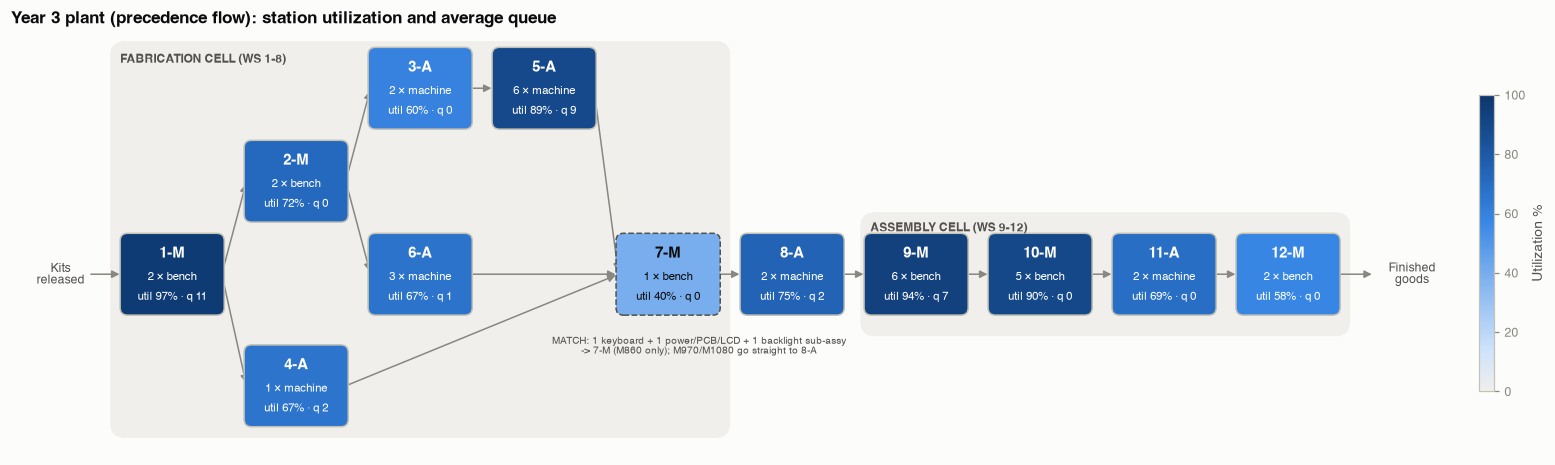

In [2]:
res = run(sc)
assert all(value == 0 for key, value in res.checks.items() if "must be 0" in key), res.checks
assert res.checks["max operator utilization (<= 1)"] <= 1 + 1e-9
assert (res.stations["Gate-blocked %"] == 0).all()
print("Accounting and operator checks:", res.checks)
P.plot_block_diagram(res); plt.show()


## 3. Throughput by product versus demand

Read each product separately: an equal M860/M970/M1080 arrival rotation can meet total demand while overproducing one model and underproducing another. Weekly output fluctuates with setups, maintenance, and scrap.

,Finished,Per week,Demand per week,% of demand,Avg flow time (hr),P90 flow time (hr)
Model,,,,,,
M860,"9,225.000","1,153.125","1,277.540",0.903,2.379,2.915
M970,"9,930.000","1,241.250","1,105.920",1.122,2.024,2.863
M1080,"9,754.000","1,219.250","1,230.320",0.991,2.423,3.241
Total,"28,909.000","3,613.625","3,613.780",1.000,2.272,3.013


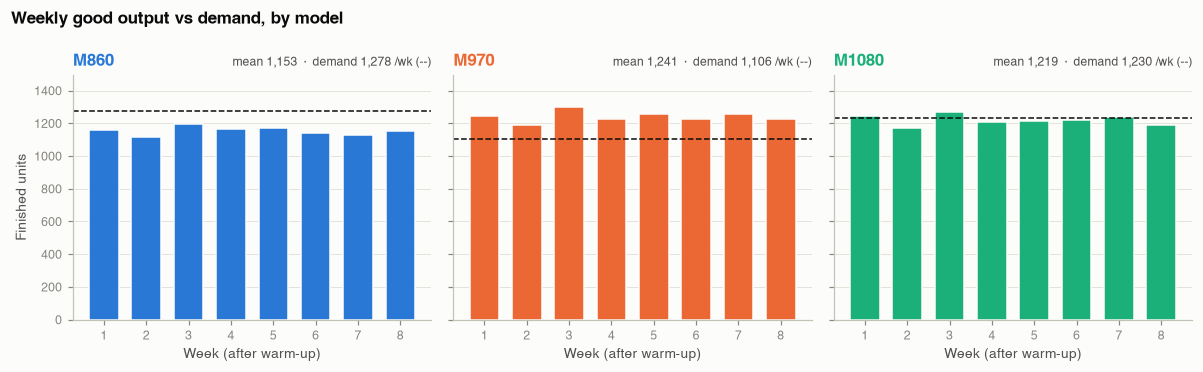

In [3]:
display(res.throughput)
P.plot_throughput(res); plt.show()


## 4. Queues, WIP, and matching

Daily station bars show waiting units by product; the detailed lines show the time pattern. No lot gates are used in this policy.

**Waiting at the match** is the component buffer after fabrication branches 4-A, 5-A, and 6-A. It is separate from station 7. One keyboard, one power/PCB/LCD, and one backlight subassembly from the same product lot must be available before an assembly moves to 7-M (M860) or directly to 8-A (M970/M1080). Waiting components count as WIP and occupy no operators or machines.

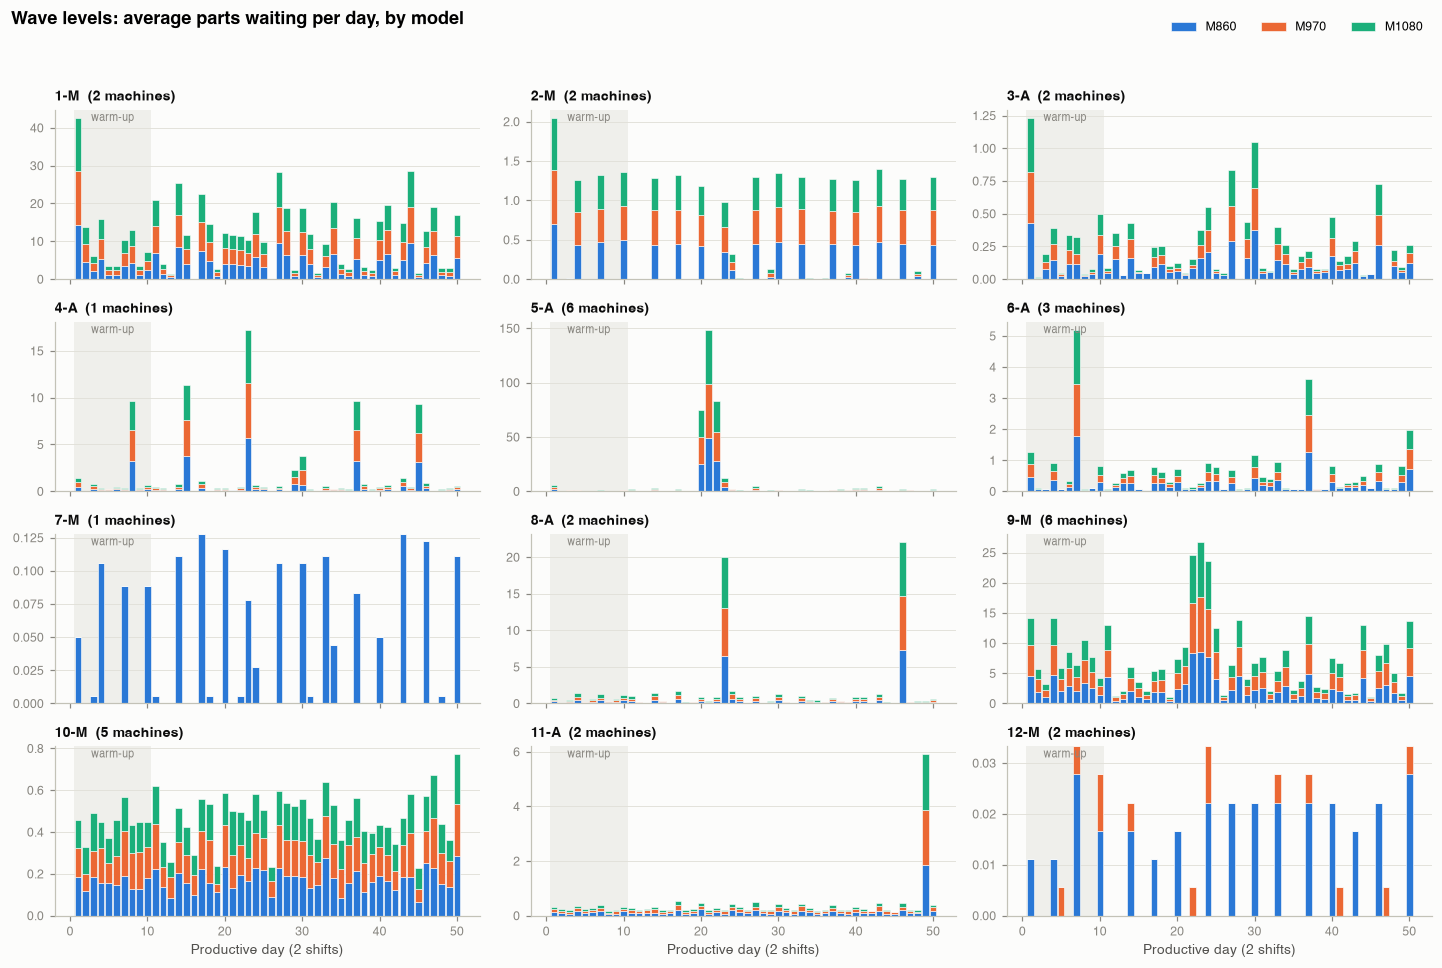

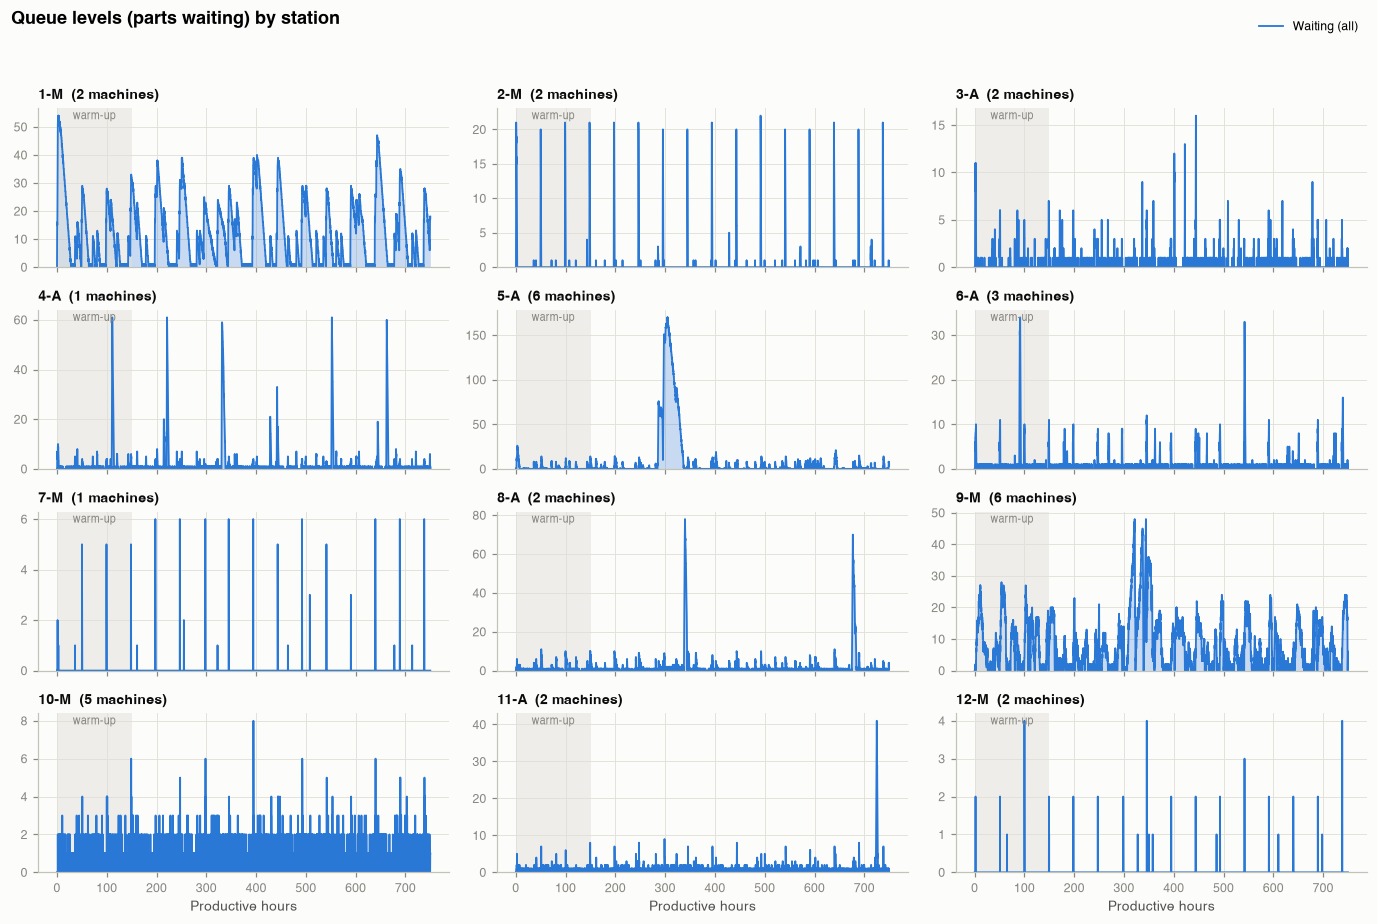

In [4]:
P.plot_wave_levels(res); plt.show()
P.plot_queue_lines(res, gated=False); plt.show()


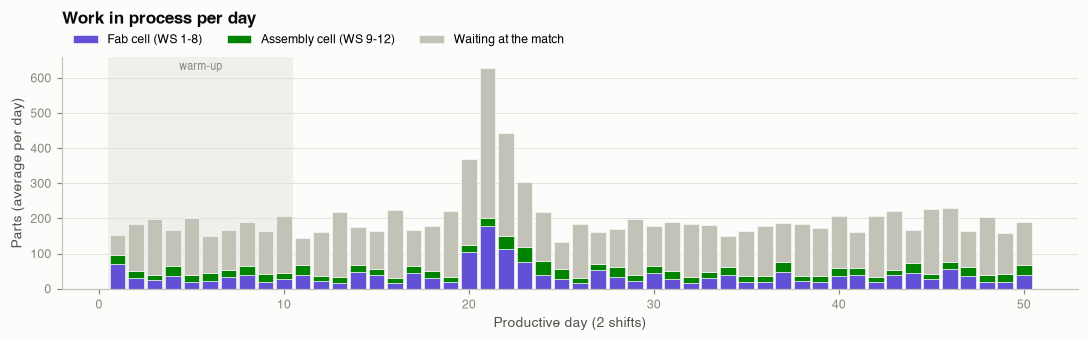

WIP near measurement start/end: 183 / 170 items
Net change: -13 items
Time-average WIP: 208.9 component/assembly items


In [5]:
P.plot_wip(res); plt.show()
window = res.trace[res.trace.t >= sc.warmup_min]
print(f"WIP near measurement start/end: {window.iloc[0]['WIP']:,.0f} / {window.iloc[-1]['WIP']:,.0f} items")
print(f"Net change: {window.iloc[-1]['WIP'] - window.iloc[0]['WIP']:,.0f} items")
print(f"Time-average WIP: {res.kpis['WIP|Average WIP (parts)']:,.1f} component/assembly items")


## 5. Station utilization and capacity

Utilization includes processing plus setup. The historical Phase 1 comparison and processing-only capacity estimates are reference values based on the original planned mix; the actual throughput, queue, and state-time measurements reflect this experiment's equal-thirds arrivals. Capacity bars exclude setup, operator waiting, and downtime.

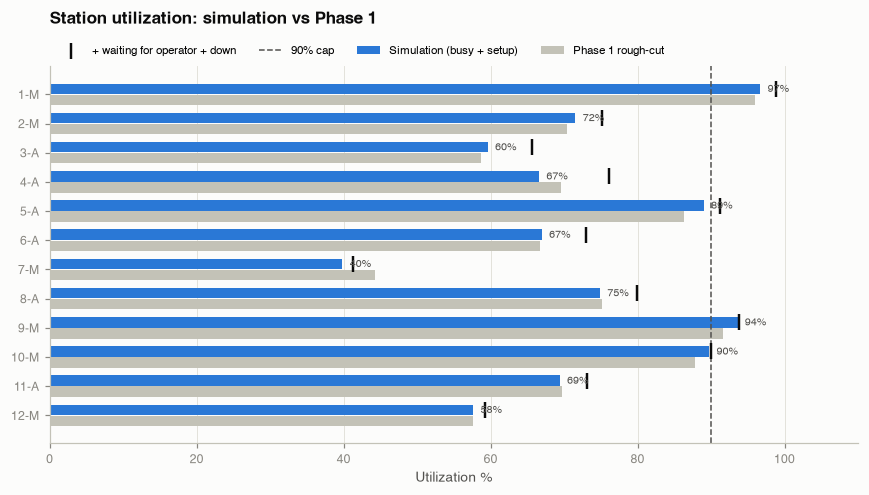

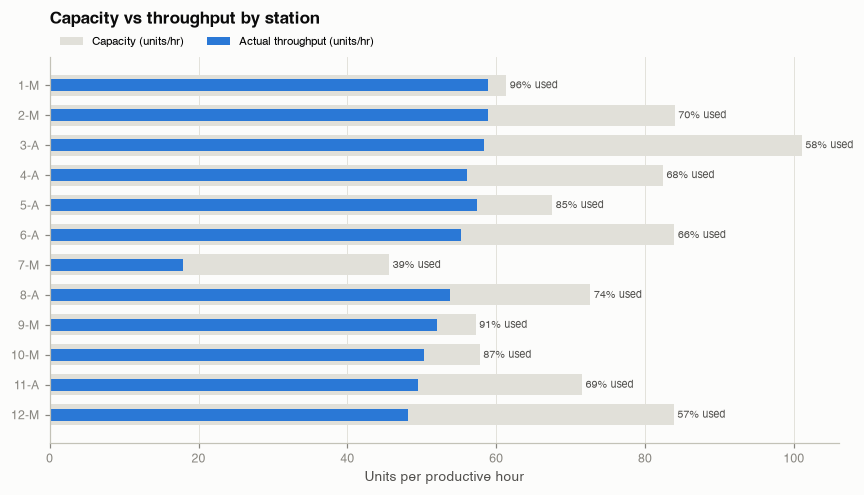

,Cell,Machines,Utilization,Busy %,Setup %,WaitOp %,Down %,Idle %,Capacity (units/hr),Throughput (units/hr),Avg queue,Max queue,Avg wait (min),Wait for operator (min/part),Group setups
Station,,,,,,,,,,,,,,,
1-M,Fab,2,0.967,0.962,0.006,0.022,0.000,0.011,61.332,58.863,11.357,48.000,11.576,0.044,12
2-M,Fab,2,0.716,0.708,0.007,0.035,0.001,0.248,83.978,58.863,0.396,22.000,0.404,0.072,12
3-A,Fab,2,0.596,0.593,0.003,0.054,0.006,0.344,101.043,58.420,0.228,17.000,0.234,0.110,44
4-A,Fab,1,0.666,0.663,0.003,0.085,0.010,0.239,82.383,56.012,1.691,62.000,1.811,0.091,44
5-A,Fab,6,0.890,0.875,0.015,0.015,0.007,0.088,67.506,57.477,9.110,171.000,9.510,0.076,44
6-A,Fab,3,0.670,0.666,0.004,0.048,0.012,0.270,83.916,55.258,0.506,33.000,0.550,0.157,12
7-M,Fab,1,0.398,0.394,0.004,0.014,0.001,0.587,45.605,17.965,0.034,6.000,0.114,0.045,12
8-A,Fab,2,0.749,0.745,0.004,0.044,0.006,0.201,72.631,53.790,1.593,80.000,1.777,0.097,44
9-M,Asm,6,0.936,0.934,0.002,0.002,0.000,0.062,57.228,51.992,7.399,49.000,8.539,0.012,12


In [6]:
P.plot_utilization(res); plt.show()
P.plot_capacity(res); plt.show()
display(res.stations[["Cell", "Machines", "Utilization", "Busy %", "Setup %", "WaitOp %", "Down %", "Idle %",
                      "Capacity (units/hr)", "Throughput (units/hr)", "Avg queue", "Max queue", "Avg wait (min)",
                      "Wait for operator (min/part)", "Group setups"]])


## 6. Machine states and individual machines

The station chart aggregates parallel machines. The heatmap and machine chart expose uneven loading. During a group setup, all participating machines are in Setup; while the setup team is being acquired, they are in Waiting for operator.

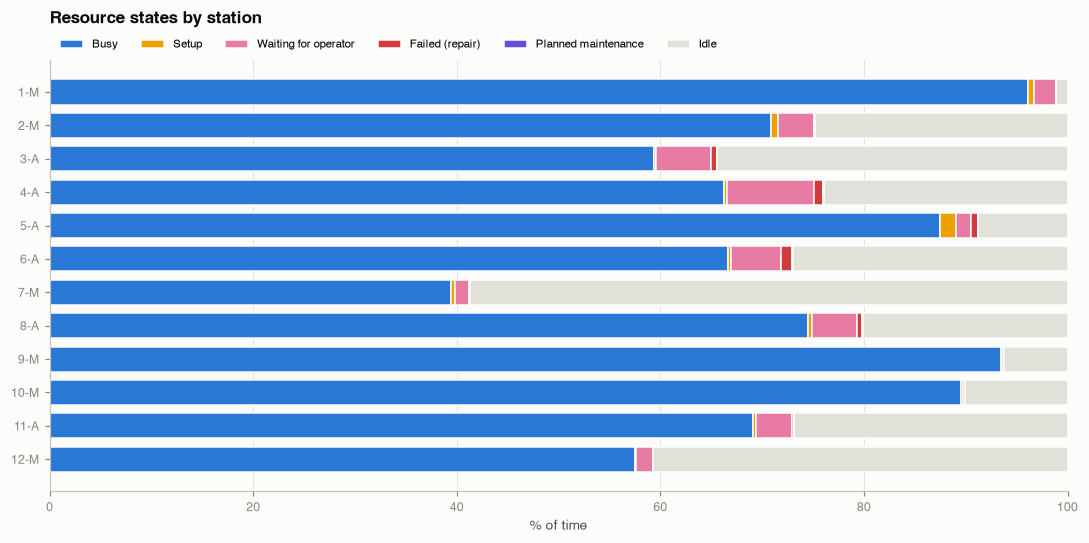

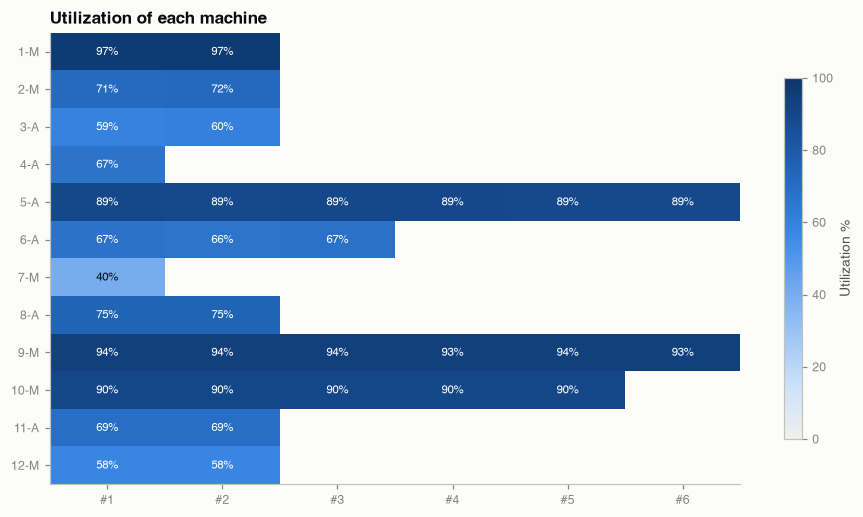

In [7]:
P.plot_machine_states(res, by="station"); plt.show()
P.plot_machine_heatmap(res); plt.show()


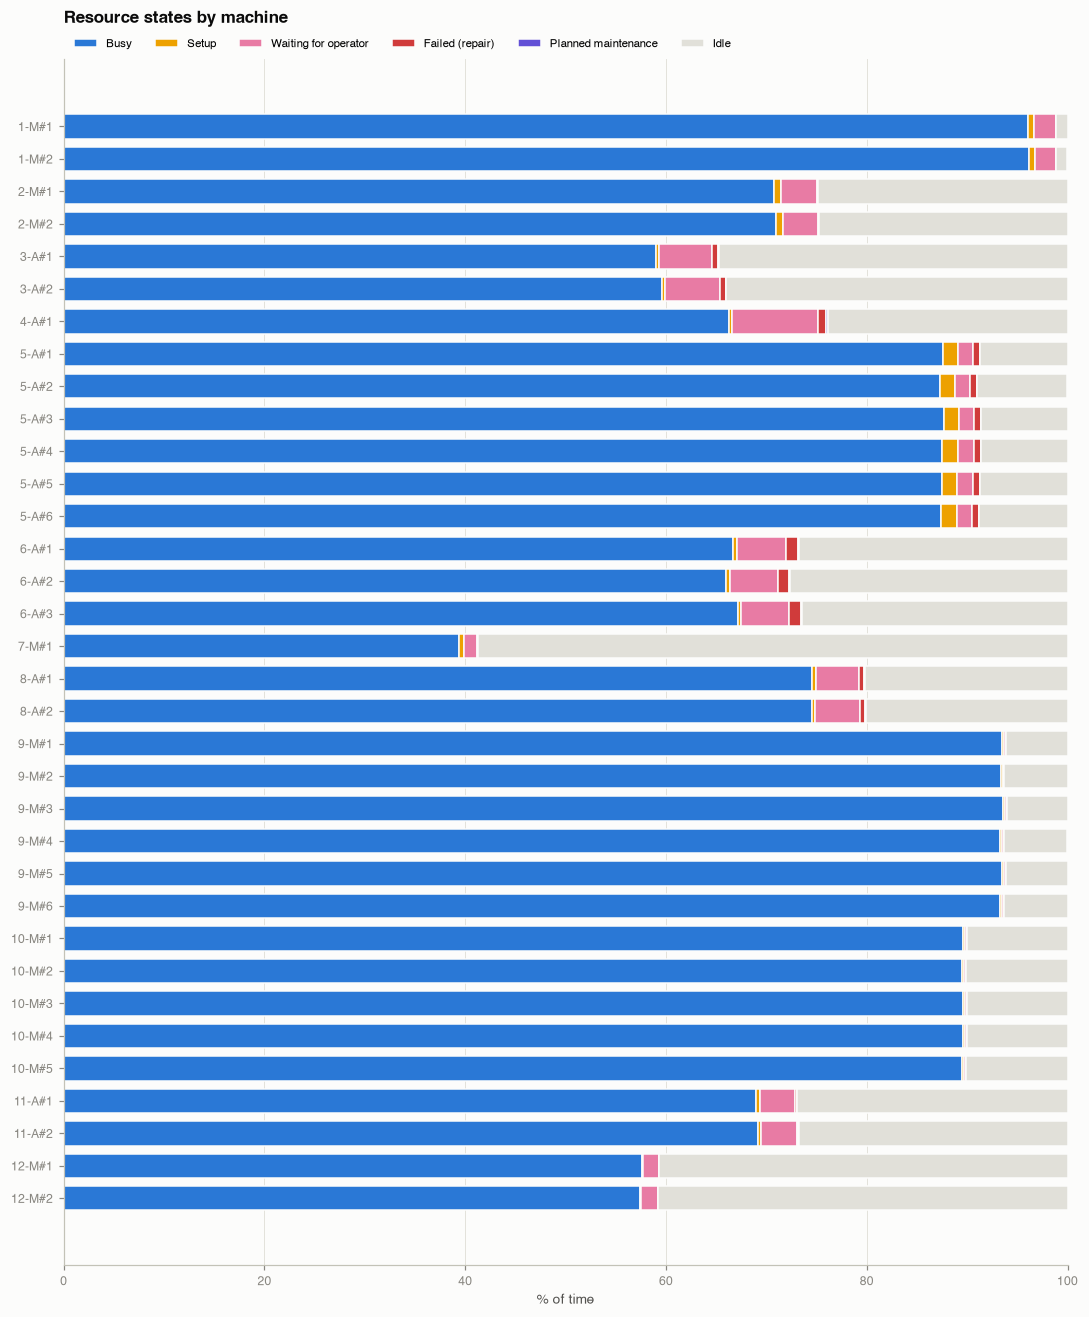

,Station,Busy %,Setup %,WaitOp %,Idle %,Failed %,PM %,Utilization,Units,Setups,Failures,PMs
Machine,,,,,,,,,,,,
1-M#1,1-M,0.961,0.006,0.022,0.011,0.000,0.000,0.967,17647,12,0,0
1-M#2,1-M,0.962,0.006,0.021,0.011,0.000,0.000,0.967,17671,12,0,0
2-M#1,2-M,0.708,0.007,0.035,0.249,0.001,0.000,0.715,17633,12,4,0
2-M#2,2-M,0.709,0.007,0.035,0.247,0.001,0.000,0.716,17685,12,4,0
3-A#1,3-A,0.590,0.003,0.053,0.348,0.006,0.000,0.593,17160,44,7,1
3-A#2,3-A,0.596,0.003,0.055,0.340,0.006,0.000,0.599,17892,44,7,1
4-A#1,4-A,0.663,0.003,0.085,0.239,0.008,0.002,0.666,33607,44,5,3
5-A#1,5-A,0.876,0.015,0.015,0.088,0.007,0.000,0.891,5632,44,2,0
5-A#2,5-A,0.873,0.015,0.015,0.090,0.007,0.000,0.888,5659,44,2,0


In [8]:
P.plot_machine_states(res, by="machine"); plt.show()
display(res.machines)


## 7. Operator workload and activity

Setup crews draw from the same cell operator pools used for normal processing. Daily busy-operator plots show demand against staffing. Gantt charts show the first four logged hours after warm-up, with colors indicating station assignment; simultaneous team assignments appear on multiple operator rows.

,Crew per shift,Avg busy,Peak busy,Utilization,Avg WIP in cell,Avg wait for operator (min/part),Avg wait for machine (min/part)
Cell,,,,,,,
Fab,7,6.169,7.000,0.881,39.862,0.090,3.588
Asm,13,11.622,13.000,0.894,21.037,0.037,2.489


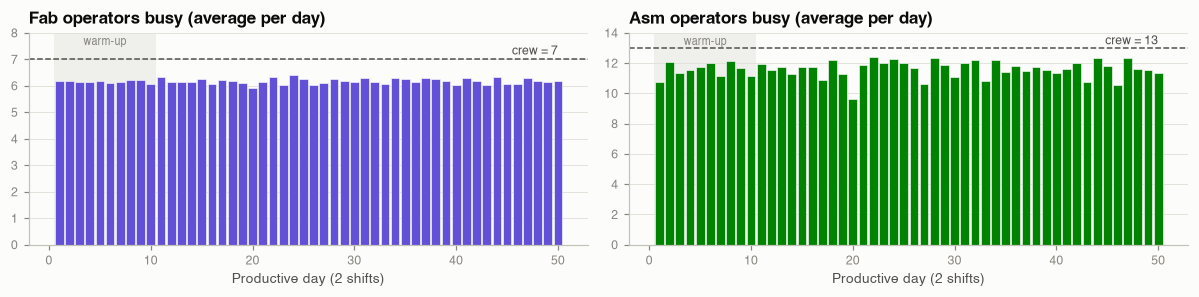

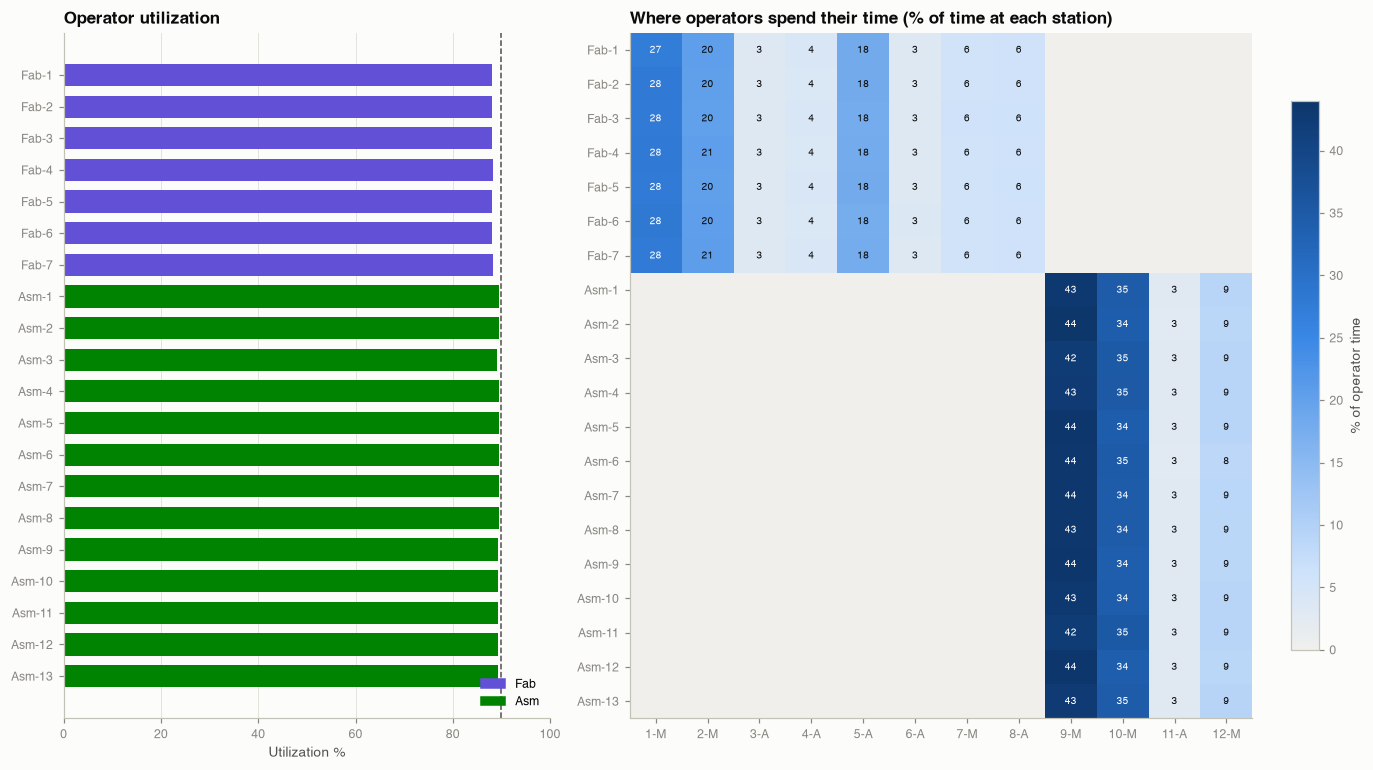

,Cell,Busy (hr),Utilization,Main station,1-M hr,2-M hr,3-A hr,4-A hr,5-A hr,6-A hr,7-M hr,8-A hr,9-M hr,10-M hr,11-A hr,12-M hr
Fab-1,Fab,528.363,0.881,1-M,163.300,122.900,19.000,23.800,109.000,20.300,34.800,35.300,0.000,0.000,0.000,0.000
Fab-2,Fab,528.687,0.881,1-M,166.100,121.700,19.200,23.600,108.500,20.300,33.800,35.400,0.000,0.000,0.000,0.000
Fab-3,Fab,528.434,0.881,1-M,165.400,121.500,19.400,24.200,106.200,20.200,35.300,36.300,0.000,0.000,0.000,0.000
Fab-4,Fab,529.204,0.882,1-M,166.600,123.200,18.800,23.500,107.400,20.200,34.000,35.600,0.000,0.000,0.000,0.000
Fab-5,Fab,528.177,0.880,1-M,165.200,122.100,18.900,24.200,108.200,20.400,33.000,36.200,0.000,0.000,0.000,0.000
Fab-6,Fab,528.709,0.881,1-M,168.400,122.900,18.600,23.400,105.700,20.600,33.800,35.400,0.000,0.000,0.000,0.000
Fab-7,Fab,529.624,0.883,1-M,165.600,124.300,19.200,23.800,106.700,19.900,34.300,35.700,0.000,0.000,0.000,0.000
Asm-1,Asm,537.202,0.895,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,258.400,207.700,17.000,54.100
Asm-2,Asm,537.240,0.895,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,263.700,205.000,16.400,52.100
Asm-3,Asm,534.683,0.891,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,254.100,209.700,17.200,53.700


In [9]:
display(res.cells)
P.plot_operators_busy(res); plt.show()
P.plot_operators(res); plt.show()
display(res.operators.join((res.op_station / 60).round(1).add_suffix(" hr")))


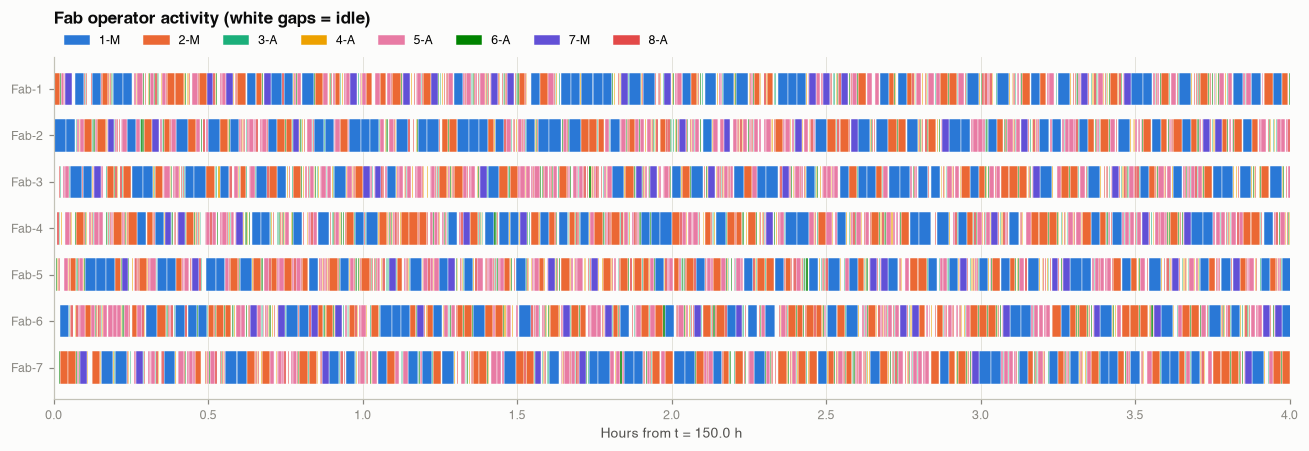

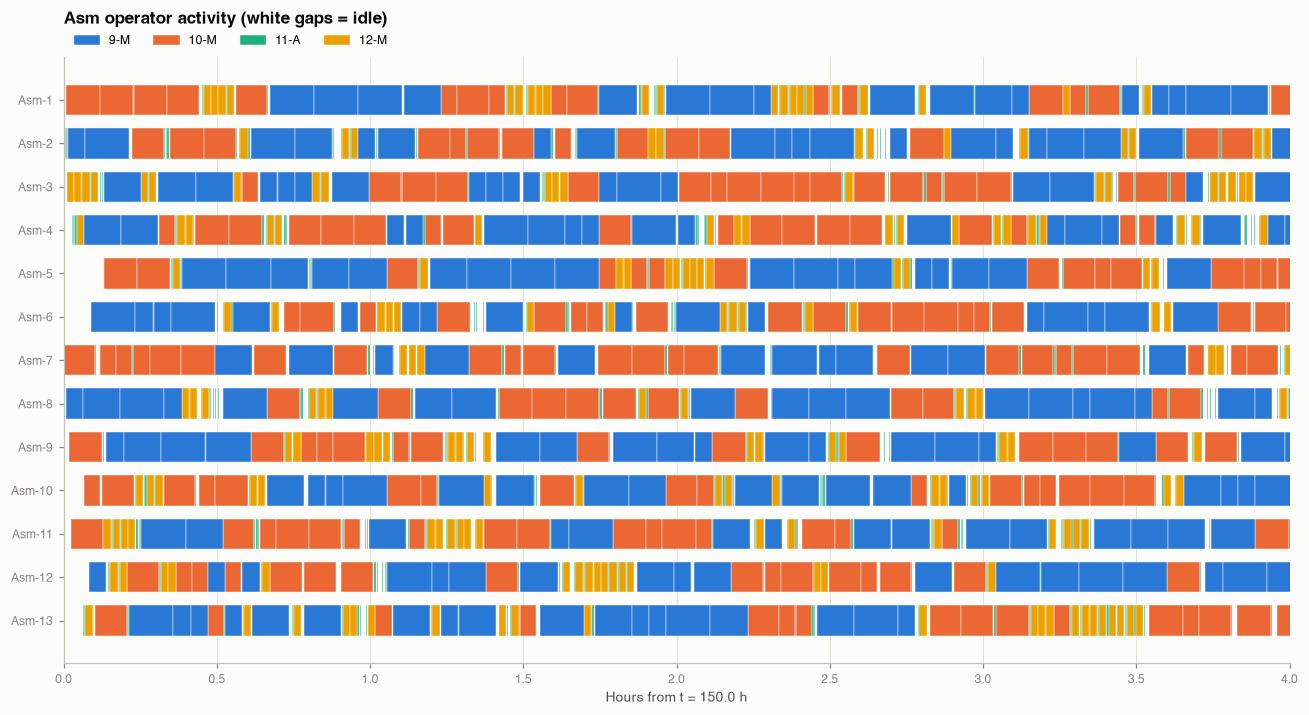

In [10]:
P.plot_operator_gantt(res, cell="Fab", hours=4); plt.show()
P.plot_operator_gantt(res, cell="Asm", hours=4); plt.show()


## 8. Station-group setups and team labor

Group setups count whole-station events during the measurement window. Machine setups count each participating machine: one event at 5-A contributes six machine setups. The event table and crew chart use the first logged week after warm-up; the event-count chart uses the complete eight-week measurement period.

,Station,Lot,Model,Start,End,Crew,Elapsed min,Operator min
0,1-M,16,M860,"11,784.981","11,801.648",2,16.667,33.333
1,10-M,16,M860,"11,876.383","11,881.939",5,5.556,27.778
2,11-A,14,M1080,"9,683.469","9,687.219",2,3.750,7.500
3,11-A,15,M970,"10,744.112","10,746.612",2,2.500,5.000
4,11-A,16,M860,"11,885.097","11,887.597",2,2.500,5.000
5,11-A,17,M1080,"12,097.829","12,101.579",2,3.750,7.500
6,11-A,18,M970,"12,892.437","12,894.937",2,2.500,5.000
7,12-M,16,M860,"11,889.271","11,894.033",2,4.762,9.524
8,2-M,16,M860,"11,803.390","11,824.443",2,21.053,42.105
9,3-A,14,M1080,"9,622.628","9,625.485",2,2.857,5.714


,Machines,Group setups,Setups,Setup %,WaitOp %
Station,,,,,
1-M,2,12,24,0.006,0.022
2-M,2,12,24,0.007,0.035
3-A,2,44,88,0.003,0.054
4-A,1,44,44,0.003,0.085
5-A,6,44,264,0.015,0.015
6-A,3,12,36,0.004,0.048
7-M,1,12,12,0.004,0.014
8-A,2,44,88,0.004,0.044
9-M,6,12,72,0.002,0.002


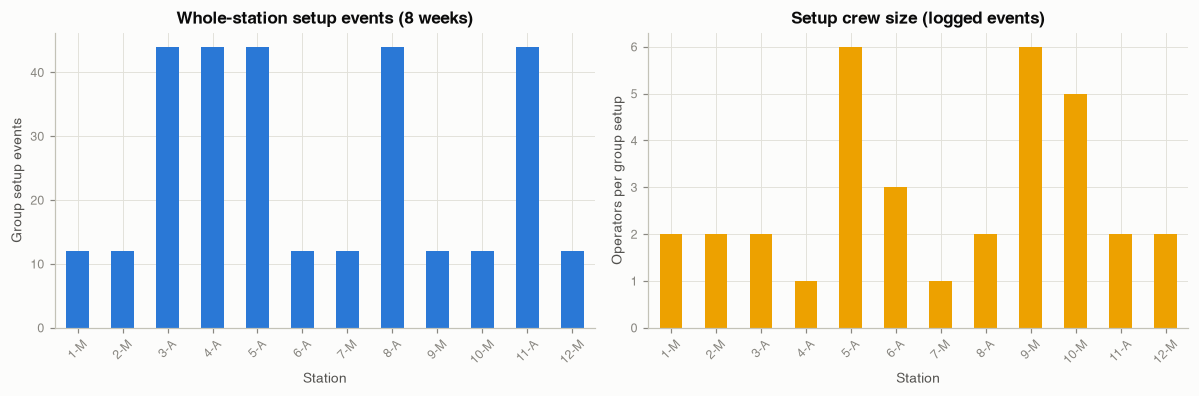

In [11]:
setup_tasks = res.op_log[res.op_log.Task == "setup"].copy()
events = pd.DataFrame()
if not setup_tasks.empty:
    events = setup_tasks.groupby(["Station", "Lot", "Model", "Start", "End"]).agg(Crew=("Operator", "nunique")).reset_index()
    events["Elapsed min"] = events.End - events.Start
    events["Operator min"] = events["Elapsed min"] * events.Crew
    display(events.head(25))
display(res.stations[["Machines", "Group setups", "Setups", "Setup %", "WaitOp %"]])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
res.stations["Group setups"].reindex(STATIONS).plot.bar(ax=axes[0], color="#2a78d6", rot=45)
axes[0].set_title("Whole-station setup events (8 weeks)")
axes[0].set_ylabel("Group setup events")
if not events.empty:
    observed = events.groupby("Station").Crew.mean().reindex(STATIONS)
    observed.plot.bar(ax=axes[1], color="#eda100", rot=45)
axes[1].set_title("Setup crew size (logged events)")
axes[1].set_ylabel("Operators per group setup")
fig.tight_layout(); plt.show()


## 9. Scrap, spare components, and lot completion

Scrap is measured per entity: a kit, component, or assembled display. Unneeded branch outputs are counted as spare; unmatched components left when their accounting group closes are counted separately. EOQ identifiers are accounting and matching groups, not station processing restrictions.

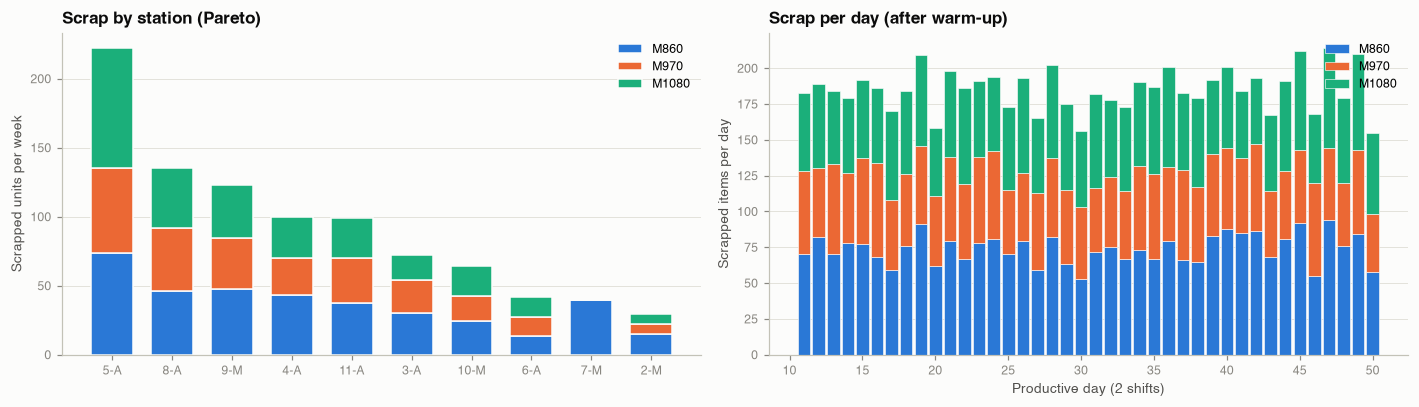

Units per week  Invested_min per week  Labor_dollars per week
Station Item                         Model                                                               
10-M    Display assembly             M1080          21.900                882.300                 177.600
                                     M860           24.100                534.700                 119.200
                                     M970           18.400                624.700                 127.100
11-A    Display assembly             M1080          28.500              1,200.100                 231.200
                                     M860           37.600                896.900                 191.500
                                     M970           32.600              1,160.500                 230.500
2-M     LCD/PCB set                  M1080           7.400                 29.000                   7.500
                                     M860           14.900                 42.800                  11.000
                                     M970            7.400                 25.100                   6.500
3-A     Power strip/PCB/LCD sub-assy M1080          17.900                100.500                  19.600
                                     M860           30.100                103.700                  24.000
                                     M970           23.900                114.700                  22.400
4-A     Keyboard sub-assy            M1080          29.900                 88.600                  19.800
                                     M860           43.000                116.600                  23.800
                                     M970           27.000                 63.100                  14.100
5-A     Power strip/PCB/LCD sub-assy M1080          87.000              1,120.100                 127.100
                                     M860           74.000                454.200                  85.800
                                     M970           61.100                688.400                  79.200
6-A     Backlight/sensor sub-assy    M1080          14.900                107.800                  16.300
                                     M860           13.200                 54.600                  10.500
                                     M970           13.900                 74.400                  12.900
7-M     Display assembly             M860           39.200                560.700                 112.200
8-A     Display assembly             M1080          43.500              1,094.400                 151.000
                                     M860           46.000                719.200                 145.300
                                     M970           45.500                933.500                 130.900
9-M     Display assembly             M1080          38.100              1,288.700                 227.500
                                     M860           47.500                902.800                 196.100
                                     M970           37.200              1,035.100                 188.400

,EOQ,Kits,Finished,Finished / EOQ,Short of EOQ,Scrapped,Spare,Unmatched,Yield (finished / kits),Planned yield,Lot flow time (hr)
Model,,,,,,,,,,,
M1080,655.000,785.000,651.222,0.994,5.833,152.722,93.778,10.833,0.830,0.835,40.714
M860,754.000,963.000,749.933,0.995,7.600,245.533,105.267,16.600,0.779,0.783,49.488
M970,596.000,699.000,589.952,0.990,6.857,126.810,58.381,11.524,0.844,0.853,36.420


In [12]:
P.plot_scrap(res); plt.show()
weeks = res.T / 4500
scr = res.scrap.groupby(["Station", "Item", "Model"]).agg(Units=("Part", "count"),
    Invested_min=("Invested min", "sum"), Labor_dollars=("Labor $", "sum"))
display((scr / weeks).round(1).rename(columns=lambda c: c + " per week"))
lots = res.lots.dropna(subset=["Done"])
display(lots.groupby("Model")[["EOQ", "Kits", "Finished", "Finished / EOQ", "Short of EOQ", "Scrapped", "Spare",
    "Unmatched", "Yield (finished / kits)", "Planned yield", "Lot flow time (hr)"]].mean())


## 10. Individual-display flow time

Flow time starts at the actual arrival of the oldest constituent kit and ends at finished-display departure. It includes setup, queues, matching, downtime, and processing. The distribution is distinct from whole-lot completion time.

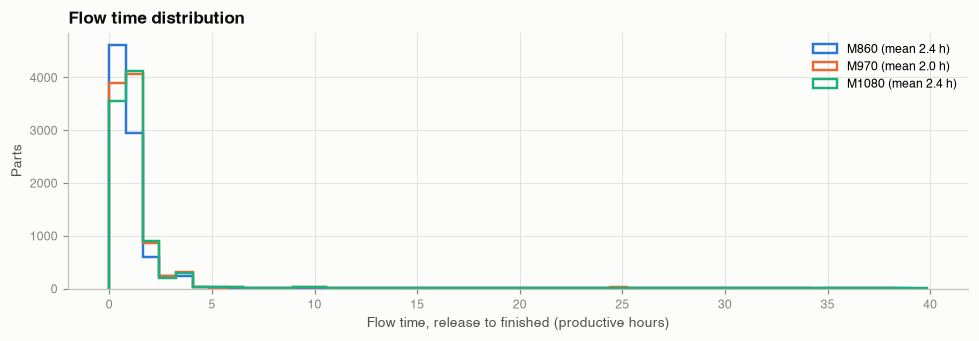

,Avg flow time (hr),P90 flow time (hr)
Model,,
M860,2.379,2.915
M970,2.024,2.863
M1080,2.423,3.241
Total,2.272,3.013


In [13]:
P.plot_flow_time(res); plt.show()
display(res.throughput[["Avg flow time (hr)", "P90 flow time (hr)"]])


## 11. Replications and policy comparisons

The direct test of the assumptions compares the two unit-rotation policies with identical total kit rate and arrival order. Continuous product runs are an additional reference and retain the earlier demand-weighted mix. Each policy uses ten replications with seeds 1–10. Event ordering changes can change individual scrap outcomes. Reported half-widths are 95% confidence intervals for the mean.

In [14]:
policies = {
    "Continuous product runs": get_scenario(YEAR, release_mode="continuous"),
    "Unit rotation: machine changeovers": get_scenario(YEAR, release_mode="cyclic"),
    "Unit rotation: assumptions": sc,
}
summaries = {}
for name, scenario in policies.items():
    print("Running:", name, flush=True)
    _, summaries[name] = run_replications(scenario, n=N_REPS, n_jobs=N_JOBS)
keys = [
    ("WIP", "Average WIP (parts)"), ("WIP", "Ending WIP (parts)"),
    ("Throughput", "Total per week"), ("Throughput", "% of demand"),
    *[("Throughput", f"{model} per week") for model in MODELS],
    *[("Flow time (hr)", model) for model in MODELS],
    ("Operators", "Fab utilization"), ("Operators", "Asm utilization"),
]
comparison = pd.concat([summary.loc[keys, "Average"].rename(name) for name, summary in summaries.items()], axis=1)
display(comparison)
assumptions_summary = summaries["Unit rotation: assumptions"]
display(assumptions_summary.loc[keys, ["Average", "Half Width", "Minimum", "Maximum"]])
comparison.to_csv("phase2_assumptions_comparison.csv")


Running: Continuous product runs


Running: Unit rotation: machine changeovers


Running: Unit rotation: assumptions


Continuous product runs  Unit rotation: machine changeovers  Unit rotation: assumptions
Category       Statistic                                                                                                   
WIP            Average WIP (parts)                  984.301                          20,939.207                     200.230
               Ending WIP (parts)                   772.100                          34,786.000                     166.800
Throughput     Total per week                     3,608.812                             870.300                   3,615.912
               % of demand                            0.999                               0.241                       1.001
               M860 per week                      1,312.088                             276.375                   1,147.312
               M970 per week                      1,110.263                             300.175                   1,249.075
               M1080 per week                     1,186.463                             293.750                   1,219.525
Flow time (hr) M860                                  14.828                             349.612                       2.262
               M970                                  15.406                             348.600                       1.909
               M1080                                 13.784                             349.027                       2.368
Operators      Fab utilization                        0.885                               0.885                       0.881
               Asm utilization                        0.872                               0.259                       0.895

Average  Half Width   Minimum   Maximum
Category       Statistic                                                    
WIP            Average WIP (parts)   200.230       8.237   190.658   229.462
               Ending WIP (parts)    166.800       9.488   144.000   190.000
Throughput     Total per week      3,615.912       5.935 3,600.250 3,631.750
               % of demand             1.001       0.002     0.996     1.005
               M860 per week       1,147.312       3.402 1,138.250 1,153.125
               M970 per week       1,249.075       3.708 1,241.125 1,256.875
               M1080 per week      1,219.525       1.863 1,216.250 1,224.625
Flow time (hr) M860                    2.262       0.129     2.068     2.696
               M970                    1.909       0.128     1.762     2.370
               M1080                   2.368       0.096     2.205     2.689
Operators      Fab utilization         0.881       0.000     0.881     0.881
               Asm utilization         0.895       0.001     0.893     0.898

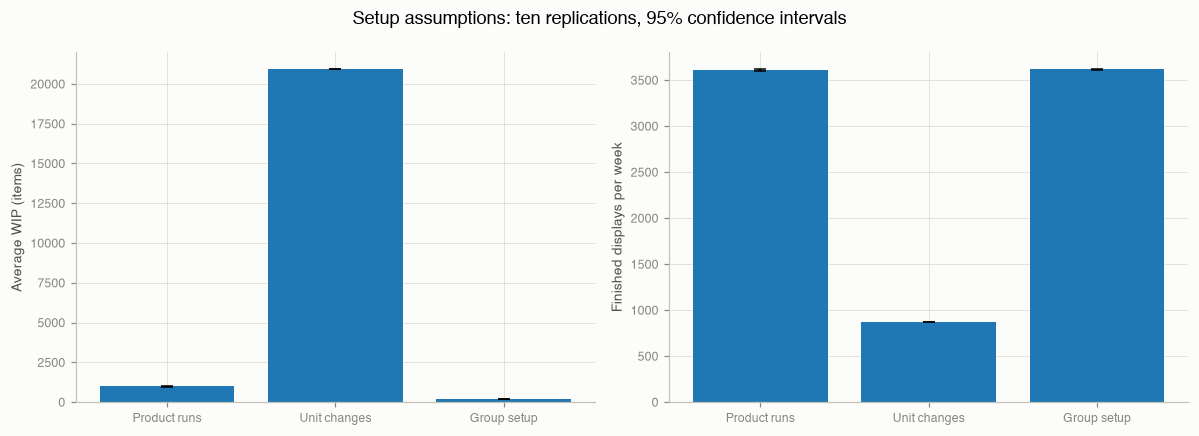

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, key, label in zip(axes, [("WIP", "Average WIP (parts)"), ("Throughput", "Total per week")],
                         ["Average WIP (items)", "Finished displays per week"]):
    means = [summary.loc[key, "Average"] for summary in summaries.values()]
    errors = [summary.loc[key, "Half Width"] for summary in summaries.values()]
    ax.bar(["Product runs", "Unit changes", "Group setup"], means, yerr=errors, capsize=4)
    ax.set_ylabel(label)
fig.suptitle("Setup assumptions: ten replications, 95% confidence intervals")
fig.tight_layout(); plt.show()


## 12. Bottlenecks across replications

Station utilization and average queues are averaged across the assumptions-policy replications. High utilization and persistent queues identify constraints; machine Setup and Waiting for operator states explain capacity losses.

,Avg utilization (10 reps),Avg queue (10 reps),Machines,Setup %,WaitOp %,Group setups
Statistic,,,,,,
1-M,0.967,11.245,2,0.006,0.022,12
9-M,0.938,7.823,6,0.002,0.002,12
10-M,0.898,0.466,5,0.002,0.002,12
5-A,0.890,6.364,6,0.015,0.015,44
8-A,0.749,1.463,2,0.004,0.044,44
2-M,0.716,0.399,2,0.007,0.035,12
11-A,0.694,0.416,2,0.004,0.035,44
6-A,0.670,0.631,3,0.004,0.048,12
4-A,0.666,1.541,1,0.003,0.085,44


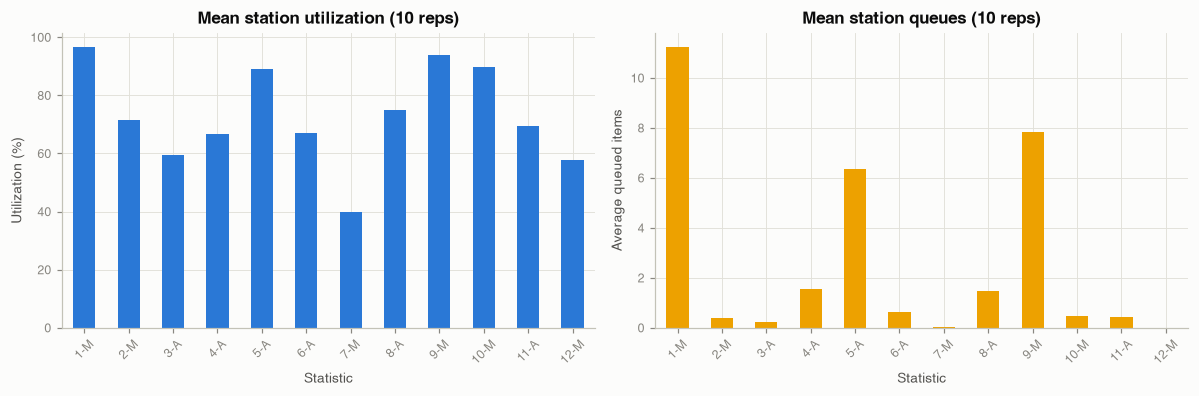

Average  Half Width   Minimum   Maximum
Category            Statistic                                                                    
Throughput          M860 per week                       1,147.312       3.402 1,138.250 1,153.125
                    M970 per week                       1,249.075       3.708 1,241.125 1,256.875
                    M1080 per week                      1,219.525       1.863 1,216.250 1,224.625
                    Total per week                      3,615.912       5.935 3,600.250 3,631.750
                    % of demand                             1.001       0.002     0.996     1.005
Flow time (hr)      M860                                    2.262       0.129     2.068     2.696
                    M970                                    1.909       0.128     1.762     2.370
                    M1080                                   2.368       0.096     2.205     2.689
WIP                 Average WIP (parts)                   200.230       8.237   190.658   229.462
                    Ending WIP (parts)                    166.800       9.488   144.000   190.000
Operators           Fab utilization                         0.881       0.000     0.881     0.881
                    Fab wait for operator (min/part)        0.088       0.001     0.086     0.093
                    Asm utilization                         0.895       0.001     0.893     0.898
                    Asm wait for operator (min/part)        0.038       0.001     0.036     0.039
Station utilization 1-M                                     0.967       0.000     0.967     0.967
                    2-M                                     0.716       0.000     0.715     0.716
                    3-A                                     0.596       0.000     0.596     0.596
                    4-A                                     0.666       0.000     0.666     0.666
                    5-A                                     0.890       0.000     0.890     0.891
                    6-A                                     0.670       0.000     0.670     0.670
                    7-M                                     0.399       0.000     0.398     0.400
                    8-A                                     0.749       0.000     0.748     0.750
                    9-M                                     0.938       0.001     0.936     0.940
                    10-M                                    0.898       0.001     0.896     0.901
                    11-A                                    0.694       0.001     0.692     0.697
                    12-M                                    0.577       0.001     0.574     0.579
Avg queue           1-M                                    11.245       0.238    10.851    11.844
                    2-M                                     0.399       0.003     0.394     0.406
                    3-A                                     0.226       0.012     0.203     0.257
                    4-A                                     1.541       0.065     1.471     1.727
                    5-A                                     6.364       2.921     2.884    16.840
                    6-A                                     0.631       0.124     0.470     0.980
                    7-M                                     0.033       0.001     0.030     0.037
                    8-A                                     1.463       0.172     1.217     2.022
                    9-M                                     7.823       0.762     6.484    10.153
                    10-M                                    0.466       0.006     0.449     0.477
                    11-A                                    0.416       0.019     0.350     0.451
                    12-M                                    0.006       0.000     0.006     0.008
Down %              1-M                                     0.000       0.000     0.000     0.000
                    2-M                 

In [16]:
summary = assumptions_summary
avg_util = summary.xs("Station utilization").Average.rename("Avg utilization (10 reps)")
avg_q = summary.xs("Avg queue").Average.rename("Avg queue (10 reps)")
bottlenecks = pd.concat([avg_util, avg_q], axis=1).join(res.stations[["Machines", "Setup %", "WaitOp %", "Group setups"]])
display(bottlenecks.sort_values("Avg utilization (10 reps)", ascending=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
avg_util.reindex(STATIONS).mul(100).plot.bar(ax=axes[0], color="#2a78d6", rot=45)
axes[0].set_ylabel("Utilization (%)")
axes[0].set_title("Mean station utilization (10 reps)")
avg_q.reindex(STATIONS).plot.bar(ax=axes[1], color="#eda100", rot=45)
axes[1].set_ylabel("Average queued items")
axes[1].set_title("Mean station queues (10 reps)")
fig.tight_layout(); plt.show()
display(summary)
